In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import multi.modules.dplot as dplot
from statannotations.Annotator import Annotator

In [31]:
# colors
blues = np.array(sns.color_palette("Blues"))
oranges = np.array(sns.color_palette("Oranges"))

In [32]:
acc = np.load("multi/acc/comb/acc_ori.npy", allow_pickle=True).item()["xDAWN+LR"][:,:,1]
acc_p = np.load("multi/acc/comb/acc_in.npy", allow_pickle=True).item()["p"]["xDAWN+LR"]
acc_i = np.load("multi/acc/comb/acc_in.npy", allow_pickle=True).item()["i"]["xDAWN+LR"].mean(3)[:,:,1]
acc_csub = np.load("multi/acc/comb/acc_csub.npy", allow_pickle=True).item()["xDAWN+LR"][:,:,1]
acc_p_csub = np.load("multi/acc/comb/acc_cin.npy", allow_pickle=True).item()["p"]["xDAWN+LR"]
acc_i_csub = np.load("multi/acc/comb/acc_cin.npy", allow_pickle=True).item()["i"]["xDAWN+LR"].mean(3)[:,:,1]

acc2 = np.load("multi/acc/comb/acc_ori.npy", allow_pickle=True).item()["EEGConf"][:,:,1]
acc_p2 = np.load("multi/acc/comb/acc_in.npy", allow_pickle=True).item()["p"]["EEGConf"]
acc_i2 = np.load("multi/acc/comb/acc_in.npy", allow_pickle=True).item()["i"]["EEGConf"].mean(3)[:,:,1]
acc_csub2 = np.load("multi/acc/comb/acc_csub.npy", allow_pickle=True).item()["EEGConf"][:,:,1]
acc_p_csub2 = np.load("multi/acc/comb/acc_cin.npy", allow_pickle=True).item()["p"]["EEGConf"]
acc_i_csub2 = np.load("multi/acc/comb/acc_cin.npy", allow_pickle=True).item()["i"]["EEGConf"].mean(3)[:,:,1]

acc_ = {
    "xDAWN+LR\n(Within subject)":{"Perception-only":acc_p,"Imagery-only":acc_i,"Transfer":acc},
    "xDAWN+LR\n(Cross subject)":{"Perception-only":acc_p_csub,"Imagery-only":acc_i_csub,"Transfer":acc_csub},
    "EEGConf\n(Within subject)":{"Perception-only":acc_p2,"Imagery-only":acc_i2,"Transfer":acc2},
    "EEGConf\n(Cross subject)":{"Perception-only":acc_p_csub2,"Imagery-only":acc_i_csub2,"Transfer":acc_csub2},
}

In [33]:
records_binary,records_four = [], []
for st in acc_:
    for tp in acc_[st]:
        for ii in range(len(acc_[st][tp])):
            records_binary.append({
                "Setting": st,
                "Training paradigm": tp,
                "Accuracy": acc_[st][tp][ii,0]})
            records_four.append({
                "Setting": st,
                "Training paradigm": tp,
                "Accuracy": acc_[st][tp][ii,1]})
df_bin = pd.DataFrame(records_binary)
df_four = pd.DataFrame(records_four)

In [34]:
pairs = [
    (("xDAWN+LR\n(Within subject)", "Imagery-only"),("xDAWN+LR\n(Within subject)", "Transfer")),
    (("xDAWN+LR\n(Cross subject)", "Imagery-only"), ("xDAWN+LR\n(Cross subject)", "Transfer")),
    (("EEGConf\n(Within subject)", "Imagery-only"),("EEGConf\n(Within subject)", "Transfer")),
    (("EEGConf\n(Cross subject)", "Imagery-only"), ("EEGConf\n(Cross subject)", "Transfer")),
]

/tmp/ipykernel_642377/815604416.py:5: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df_bin,x="Setting",y="Accuracy",hue="Training paradigm",


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

xDAWN+LR
(Cross subject)_Imagery-only vs. xDAWN+LR
(Cross subject)_Transfer: t-test paired samples, P_val:7.401e-02 t=-1.891e+00
EEGConf
(Within subject)_Imagery-only vs. EEGConf
(Within subject)_Transfer: t-test paired samples, P_val:2.156e-02 t=-2.504e+00
EEGConf
(Cross subject)_Imagery-only vs. EEGConf
(Cross subject)_Transfer: t-test paired samples, P_val:2.009e-06 t=6.721e+00
xDAWN+LR
(Within subject)_Imagery-only vs. xDAWN+LR
(Within subject)_Transfer: t-test paired samples, P_val:2.608e-05 t=-5.505e+00


/tmp/ipykernel_642377/815604416.py:18: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df_four,x="Setting",y="Accuracy",hue="Training paradigm",


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

xDAWN+LR
(Cross subject)_Imagery-only vs. xDAWN+LR
(Cross subject)_Transfer: t-test paired samples, P_val:4.784e-01 t=7.232e-01
EEGConf
(Within subject)_Imagery-only vs. EEGConf
(Within subject)_Transfer: t-test paired samples, P_val:1.679e-02 t=-2.622e+00
EEGConf
(Cross subject)_Imagery-only vs. EEGConf
(Cross subject)_Transfer: t-test paired samples, P_val:3.874e-05 t=5.324e+00
xDAWN+LR
(Within subject)_Imagery-only vs. xDAWN+LR
(Within subject)_Transfer: t-test paired samples, P_val:9.267e-03 t=-2.896e+00


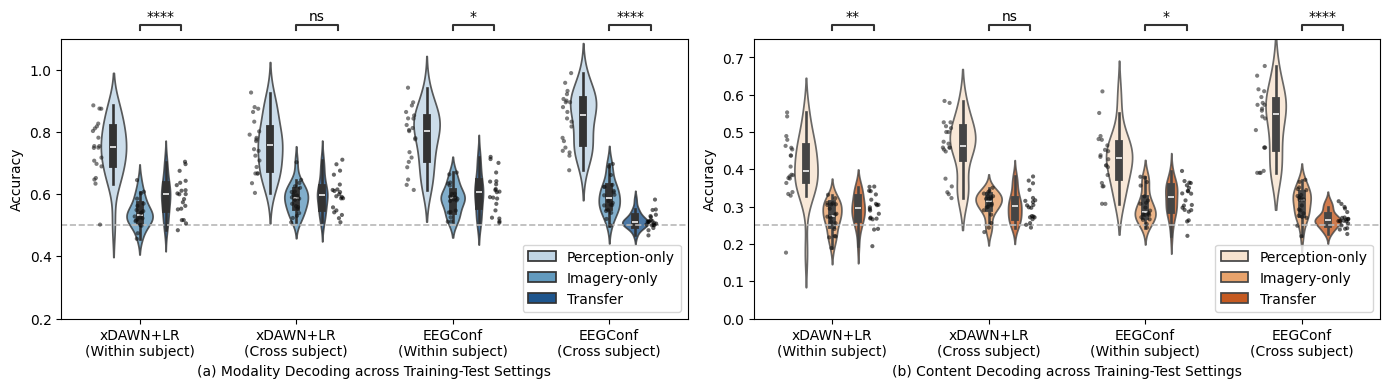

In [35]:
fig = plt.figure(figsize = (14,4))
# ---------- Binary ----------
ax = plt.subplot2grid((1, 2), (0, 0))
dplot.plot_violin(df_bin, ax, x="Setting", hue="Training paradigm", palette=list(blues[[1,3,5]]), alpha=0.8)
sns.stripplot(data=df_bin,x="Setting",y="Accuracy",hue="Training paradigm",
    dodge=True,color="black",alpha=0.6,size=3,ax=ax,legend=False)
ax.set_xlabel("(a) Modality Decoding across Training-Test Settings")
ax.axhline(0.5, color="#B8B8B8", linestyle='--', linewidth=1.2)
ax.legend(loc="lower right")
ax.set_ylim(0.2,1.1)

annotator = Annotator(ax,pairs,data=df_bin,x="Setting",y="Accuracy", hue="Training paradigm")
annotator.configure(test="t-test_paired",text_format="star",loc="outside")
annotator.apply_and_annotate()
# ---------- Four ----------
ax = plt.subplot2grid((1, 2), (0, 1))
dplot.plot_violin(df_four, ax, x="Setting", hue="Training paradigm", palette=list(oranges[[0,2,4]]), alpha=0.8)
sns.stripplot(data=df_four,x="Setting",y="Accuracy",hue="Training paradigm",
    dodge=True,color="black",alpha=0.6,size=3,ax=ax,legend=False)
ax.set_xlabel("(b) Content Decoding across Training-Test Settings")
ax.axhline(0.25, color="#B8B8B8", linestyle='--', linewidth=1.2)
ax.legend(loc="lower right")
ax.set_ylim(0.0,0.75)

annotator = Annotator(ax,pairs,data=df_four,x="Setting",y="Accuracy", hue="Training paradigm")
annotator.configure(test="t-test_paired",text_format="star",loc="outside")
annotator.apply_and_annotate()

plt.savefig("multi/fig/in.pdf", bbox_inches="tight")
plt.tight_layout()
plt.show()